# Optimización de Licitaciones Estatales en Chile
**Avance de Proyecto - Minería de Datos**

A partir de los registros históricos brutos del portal ChileCompra (2023–2025), se ejecutó el pipeline de extracción y preprocesamiento (`descarga_datos.ipynb` y `limpieza.ipynb`):
1. **Filtrado y Limpieza:** Selección de 18 variables clave y eliminación de registros con fechas corruptas o sin sector (`SINDATO`).
2. **Deduplicación:** Consolidación por `CodigoExterno` (1 fila por licitación en lugar de 1 fila por oferta/ítem), obteniendo **399.410 licitaciones únicas**.
3. **Agregación Temporal:** Construcción de la serie semanal continua (`serie_tiempo_limpia.csv`) con **1.101 registros** distribuidos en **157 semanas** y **7 sectores del Estado**.

In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

# Cargar el dataset limpio y filtrar registros sin sector asignado
df = pd.read_csv("serie_tiempo_limpia.csv")
df_km = df[df["sector"] != "SINDATO"].copy()

# Pivotear: Semanas como filas (157) y Sectores como columnas (7)
P = df_km.pivot(index="Semana", columns="sector", values="Volumen_Licitaciones").fillna(0)
fechas = pd.to_datetime(P.index.str.split("/").str[0])
P_fechas = P.copy()
P_fechas.index = fechas

print(f"Registros consolidados: {len(df_km)} | Semanas: {P.shape[0]} | Sectores activos: {P.shape[1]}")
display(df_km.head())

Registros consolidados: 1099 | Semanas: 157 | Sectores activos: 7


,Semana,sector,Volumen_Licitaciones
0,2023-01-02/2023-01-08,FFAA,118
1,2023-01-09/2023-01-15,FFAA,134
2,2023-01-16/2023-01-22,FFAA,181
3,2023-01-23/2023-01-29,FFAA,179
4,2023-01-30/2023-02-05,FFAA,189


## 1. Agrupamiento Sectorial Basado en Características Temporales (K-Means)
Para evitar la maldición de la dimensionalidad al agrupar 7 sectores sobre 157 semanas crudas, caracterizamos el comportamiento histórico y de calendario de cada sector en **4 indicadores clave**:
* **Volumen_Medio:** Promedio semanal de licitaciones publicadas (escala de demanda).
* **Coef_Variacion:** Desviación estándar dividida por la media (volatilidad relativa semanal).
* **Ratio_Febrero:** Volumen medio en febrero respecto al promedio anual (impacto estacional de verano).
* **Ratio_Fin_Anio:** Volumen medio en el último trimestre (Oct–Dic) respecto al promedio anual (ejecución presupuestaria de cierre de año).

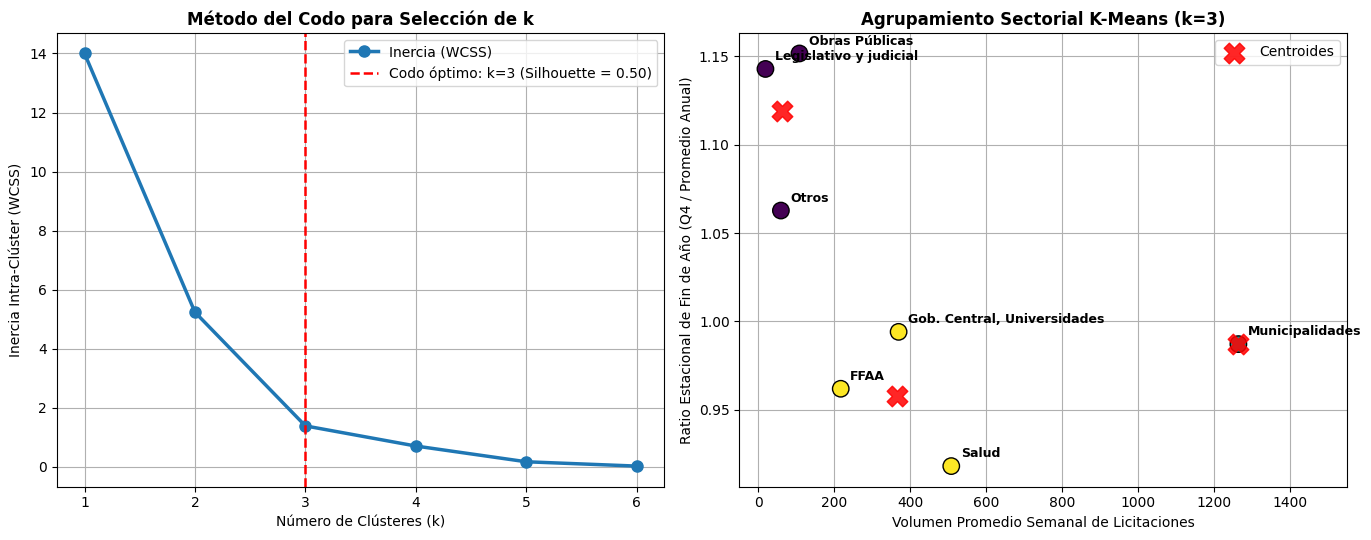

Asignación de Clústeres y Métricas por Sector:


,Volumen_Medio,Ratio_Fin_Anio,Cluster
sector,,,
Legislativo y judicial,18.465,1.143,0
Obras Públicas,108.032,1.152,0
Otros,59.185,1.063,0
Municipalidades,1264.312,0.987,1
FFAA,216.796,0.962,2
"Gob. Central, Universidades",369.255,0.994,2
Salud,507.955,0.918,2


In [10]:
# 1. Construir matriz con las 2 dimensiones clave del negocio: Escala Histórica vs. Estacionalidad de Calendario
features = pd.DataFrame(index=P.columns)
features["Volumen_Medio"] = P.mean(axis=0)
features["Ratio_Fin_Anio"] = P_fechas[P_fechas.index.month.isin([10, 11, 12])].mean(axis=0) / P.mean(axis=0)

# Estandarizar variables
scaler = StandardScaler()
X = scaler.fit_transform(features)

# 2. Evaluar desde k=1 hasta k=6 para visualizar el quiebre real del Método del Codo
K_range = range(1, 7)
inertias = []
silhouettes = {}

for k_val in K_range:
    km_temp = KMeans(n_clusters=k_val, n_init=20, random_state=42)
    lbls = km_temp.fit_predict(X)
    inertias.append(km_temp.inertia_)
    if 2 <= k_val <= 5:
        silhouettes[k_val] = silhouette_score(X, lbls)

# 3. Entrenar modelo final en el punto óptimo (k=3)
k = 3
km = KMeans(n_clusters=k, n_init=20, random_state=42)
features["Cluster"] = km.fit_predict(X)
centroides_originales = scaler.inverse_transform(km.cluster_centers_)

# Graficar Método del Codo y Mapa de Clústeres
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel Izquierdo: Método del Codo con quiebre claro en k=3
ax1 = axes[0]
ax1.plot(K_range, inertias, marker='o', markersize=8, color='tab:blue', lw=2.5, label='Inercia (WCSS)')
ax1.axvline(x=3, color='red', linestyle='--', lw=1.8, label=f'Codo óptimo: k=3 (Silhouette = {silhouettes[3]:.2f})')
ax1.set_title("Método del Codo para Selección de k", fontsize=12, fontweight='bold')
ax1.set_xlabel("Número de Clústeres (k)")
ax1.set_ylabel("Inercia Intra-Clúster (WCSS)")
ax1.set_xticks(list(K_range))
ax1.legend()

# Panel Derecho: Mapa de Clústeres en variables reales (mucho más interpretable que PCA)
ax2 = axes[1]
ax2.scatter(features["Volumen_Medio"], features["Ratio_Fin_Anio"], s=140, c=features["Cluster"], cmap='viridis', edgecolors='k', zorder=3)
ax2.scatter(centroides_originales[:, 0], centroides_originales[:, 1], marker='X', s=220, c='red', alpha=0.85, label='Centroides', zorder=4)

for nombre, row in features.iterrows():
    ax2.annotate(nombre, (row["Volumen_Medio"] + 25, row["Ratio_Fin_Anio"] + 0.005), fontsize=9, fontweight='bold')

ax2.set_title(f"Agrupamiento Sectorial K-Means (k={k})", fontsize=12, fontweight='bold')
ax2.set_xlabel("Volumen Promedio Semanal de Licitaciones")
ax2.set_ylabel("Ratio Estacional de Fin de Año (Q4 / Promedio Anual)")
ax2.set_xlim(-50, 1550)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

# Tabla resumen
print("Asignación de Clústeres y Métricas por Sector:")
display(features.round(3).sort_values("Cluster"))

## 2. Conexión Clustering y Series de Tiempo
El agrupamiento revela **3 perfiles operacionales distintos** en el Estado:
* **Clúster 0 (Demanda Institucional Estable - Escala Media/Alta):** `Salud`, `Gob. Central, Universidades` y `FFAA` (~1.094 licitaciones/semana en conjunto), con baja volatilidad relativa.
* **Clúster 1 (Demanda Estacional de Fin de Año - Escala Baja):** `Obras Públicas`, `Legislativo y judicial` y `Otros` (~186 licitaciones/semana en conjunto), caracterizados por alta volatilidad (>0.34) y un fuerte incremento en el último trimestre (`Ratio_Fin_Anio` hasta 1.15).
* **Clúster 2 (Demanda Masiva Autónoma):** `Municipalidades` (~1.264 licitaciones/semana por sí solo), que representa casi la mitad del volumen nacional y mantiene alta actividad incluso en febrero (`Ratio_Febrero` = 1.07).

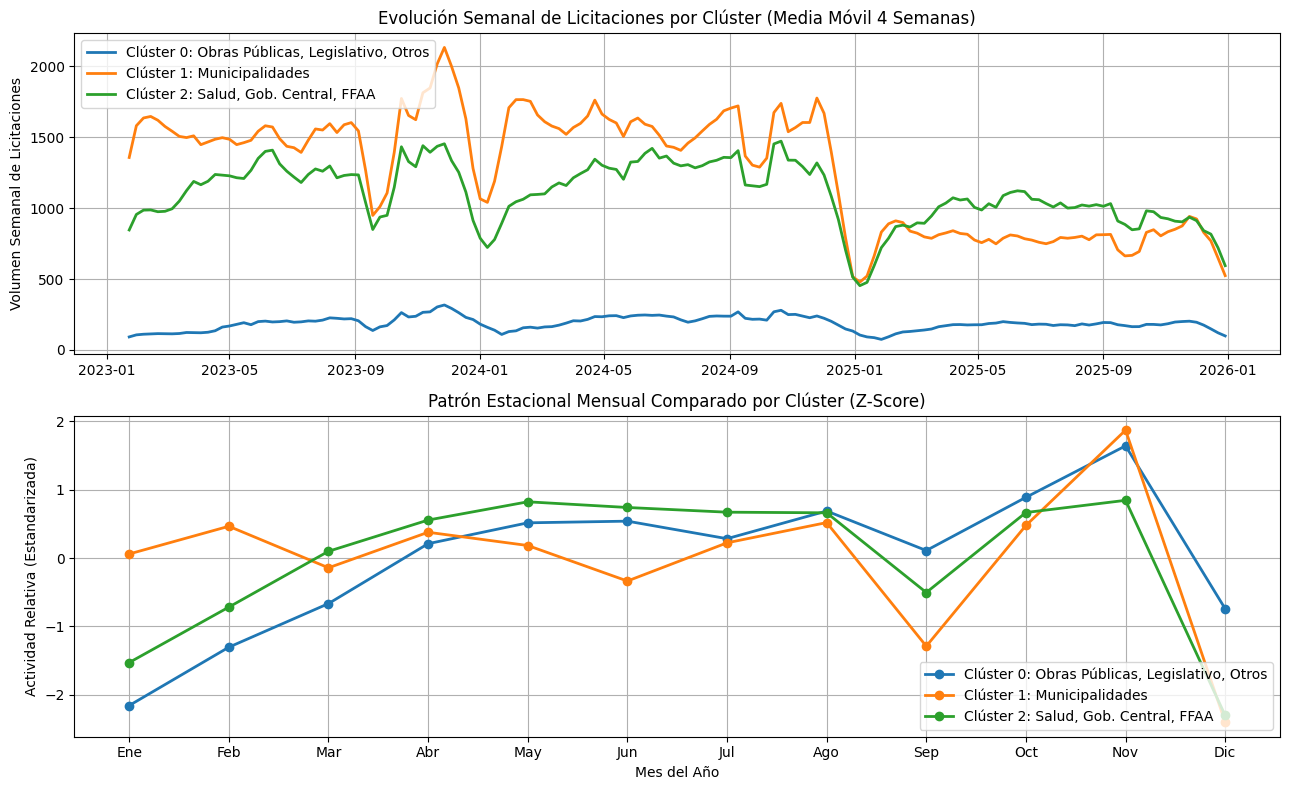

In [12]:
nombres_cluster = {
    0: "Clúster 0: Obras Públicas, Legislativo, Otros",
    1: "Clúster 1: Municipalidades",
    2: "Clúster 2: Salud, Gob. Central, FFAA"
}
colores = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}

# Construir DataFrame con las series semanales sumadas por Clúster
series_cluster = pd.DataFrame(index=P_fechas.index)
for c in range(k):
    sectores_c = features[features["Cluster"] == c].index
    series_cluster[c] = P_fechas[sectores_c].sum(axis=1)

series_cluster = series_cluster.asfreq("W-MON").fillna(0)

# Graficar series semanales (Media Móvil 4 semanas) y Perfil Estacional Mensual por Clúster
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# Gráfico 1: Evolución Semanal (Media Móvil 4 semanas) en volumen real
for c in range(k):
    mm4 = series_cluster[c].rolling(window=4).mean()
    axes[0].plot(series_cluster.index, mm4, lw=2, color=colores[c], label=nombres_cluster[c])

axes[0].set_title("Evolución Semanal de Licitaciones por Clúster (Media Móvil 4 Semanas)")
axes[0].set_ylabel("Volumen Semanal de Licitaciones")
axes[0].legend(loc="upper left")

# Gráfico 2: Comportamiento Estacional según Mes del Año (Estandarizado para comparar la forma del ciclo)
perfil_mensual = series_cluster.groupby(series_cluster.index.month).mean()
perfil_mensual_norm = pd.DataFrame(
    StandardScaler().fit_transform(perfil_mensual),
    index=perfil_mensual.index,
    columns=perfil_mensual.columns
)

meses_nombres = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
for c in range(k):
    axes[1].plot(range(1, 13), perfil_mensual_norm[c], marker='o', lw=2, color=colores[c], label=nombres_cluster[c])

axes[1].set_title("Patrón Estacional Mensual Comparado por Clúster (Z-Score)")
axes[1].set_xlabel("Mes del Año")
axes[1].set_ylabel("Actividad Relativa (Estandarizada)")
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(meses_nombres)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## 3. Descomposición Temporal y Diagnóstico para Fase 2 (ARIMA / SARIMA)
Para configurar los modelos predictivos de la Entrega Final, evaluamos la descomposición de la serie agregada (Tendencia, Estacionalidad y Residuo), verificamos la **estacionariedad mediante el test de Dickey-Fuller Aumentado (ADF)** en cada clúster y analizamos las funciones de **Autocorrelación (ACF y PACF)**.

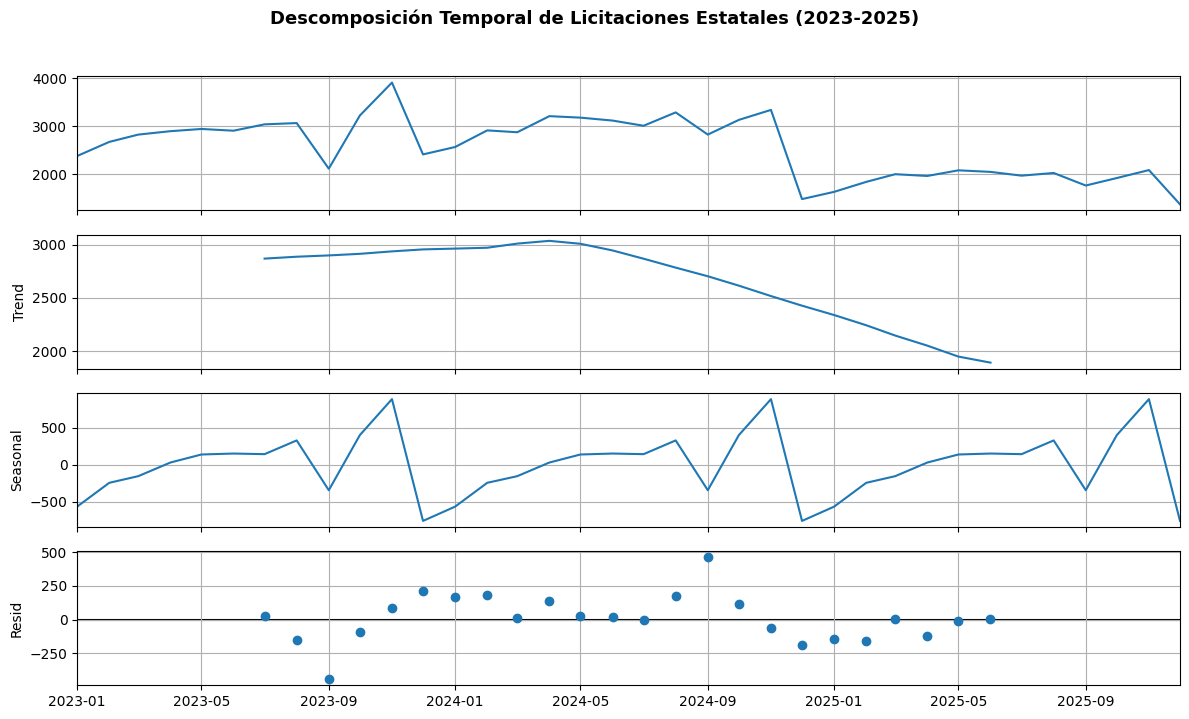

=== Diagnóstico de Estacionariedad (Test ADF) por Clúster ===


,Clúster,Volumen_Promedio_Semanal,ADF_Statistic,p-value,Estacionaria (alpha=0.05)
0,"Clúster 0: Salud, Gob. Central, FFAA",1094.0,-3.441,0.0097,Sí (d=0)
1,"Clúster 1: Obras Públicas, Legislativo, Otros",185.7,-3.301,0.0148,Sí (d=0)
2,Clúster 2: Municipalidades,1264.3,-0.830,0.8100,No (Requiere diferenciación d>=1)


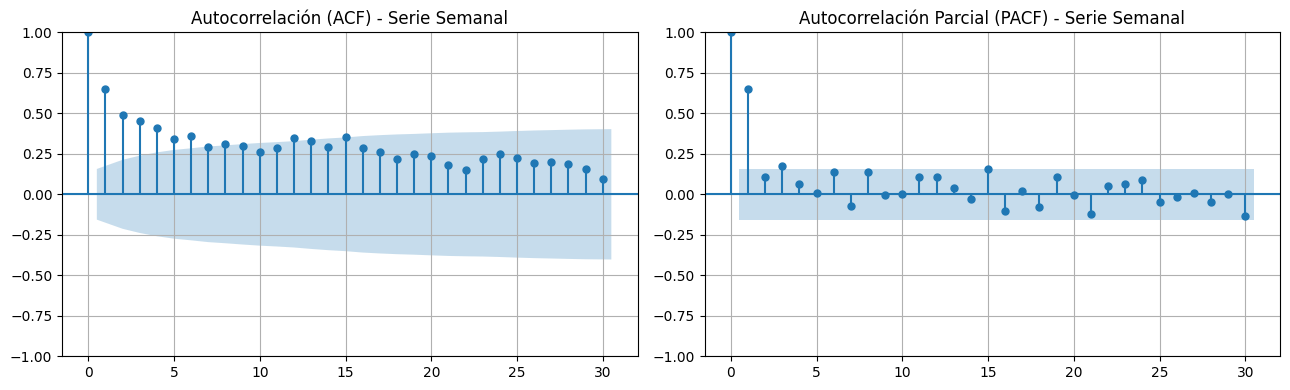

In [9]:
# 1. Serie agregada mensual para descomposición macro (Tendencia + Estacionalidad anual)
lic_total = series_cluster.sum(axis=1)
serie_mensual = lic_total.resample("MS").mean()

resultado_sd = seasonal_decompose(serie_mensual, model="additive", period=12)
fig = resultado_sd.plot()
fig.set_size_inches(12, 7)
plt.suptitle("Descomposición Temporal de Licitaciones Estatales (2023-2025)", y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Test de Estacionariedad (Dickey-Fuller Aumentado) por Clúster
print("=== Diagnóstico de Estacionariedad (Test ADF) por Clúster ===")
resultados_adf = []
for c in range(k):
    stat, p_val, _, _, _, _ = adfuller(series_cluster[c].dropna())
    es_estacionaria = "Sí (d=0)" if p_val < 0.05 else "No (Requiere diferenciación d>=1)"
    resultados_adf.append({
        "Clúster": nombres_cluster[c],
        "Volumen_Promedio_Semanal": round(series_cluster[c].mean(), 1),
        "ADF_Statistic": round(stat, 3),
        "p-value": round(p_val, 4),
        "Estacionaria (alpha=0.05)": es_estacionaria
    })
display(pd.DataFrame(resultados_adf))

# 3. Gráficos de Autocorrelación (ACF y PACF) para parametrizar ARIMA/SARIMA en la Fase 2
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(lic_total.dropna(), lags=30, ax=axes[0], title="Autocorrelación (ACF) - Serie Semanal")
plot_pacf(lic_total.dropna(), lags=30, ax=axes[1], title="Autocorrelación Parcial (PACF) - Serie Semanal")
plt.tight_layout()
plt.show()

El Clúster 0 (Salud, Gob. Central, FFAA) y el Clúster 1 (Obras Públicas, Legislativo, Otros) tienen un p-value < 0.05 (0.0097 y 0.0148), por lo que son series estacionarias. En cambio, el Clúster 2 (Municipalidades) tiene un p-value = 0.8100, lo que demuestra que no es estacionaria y tiene una tendencia propia que requiere diferenciación.

Esto demuestra empíricamente por qué nuestro enfoque híbrido (K-Means + Series de Tiempo) es superior a modelar todo el Estado junto: cada clúster tiene propiedades estadísticas distintas y requerirá distintos parámetros $(p, d, q)$ en la Fase Final.